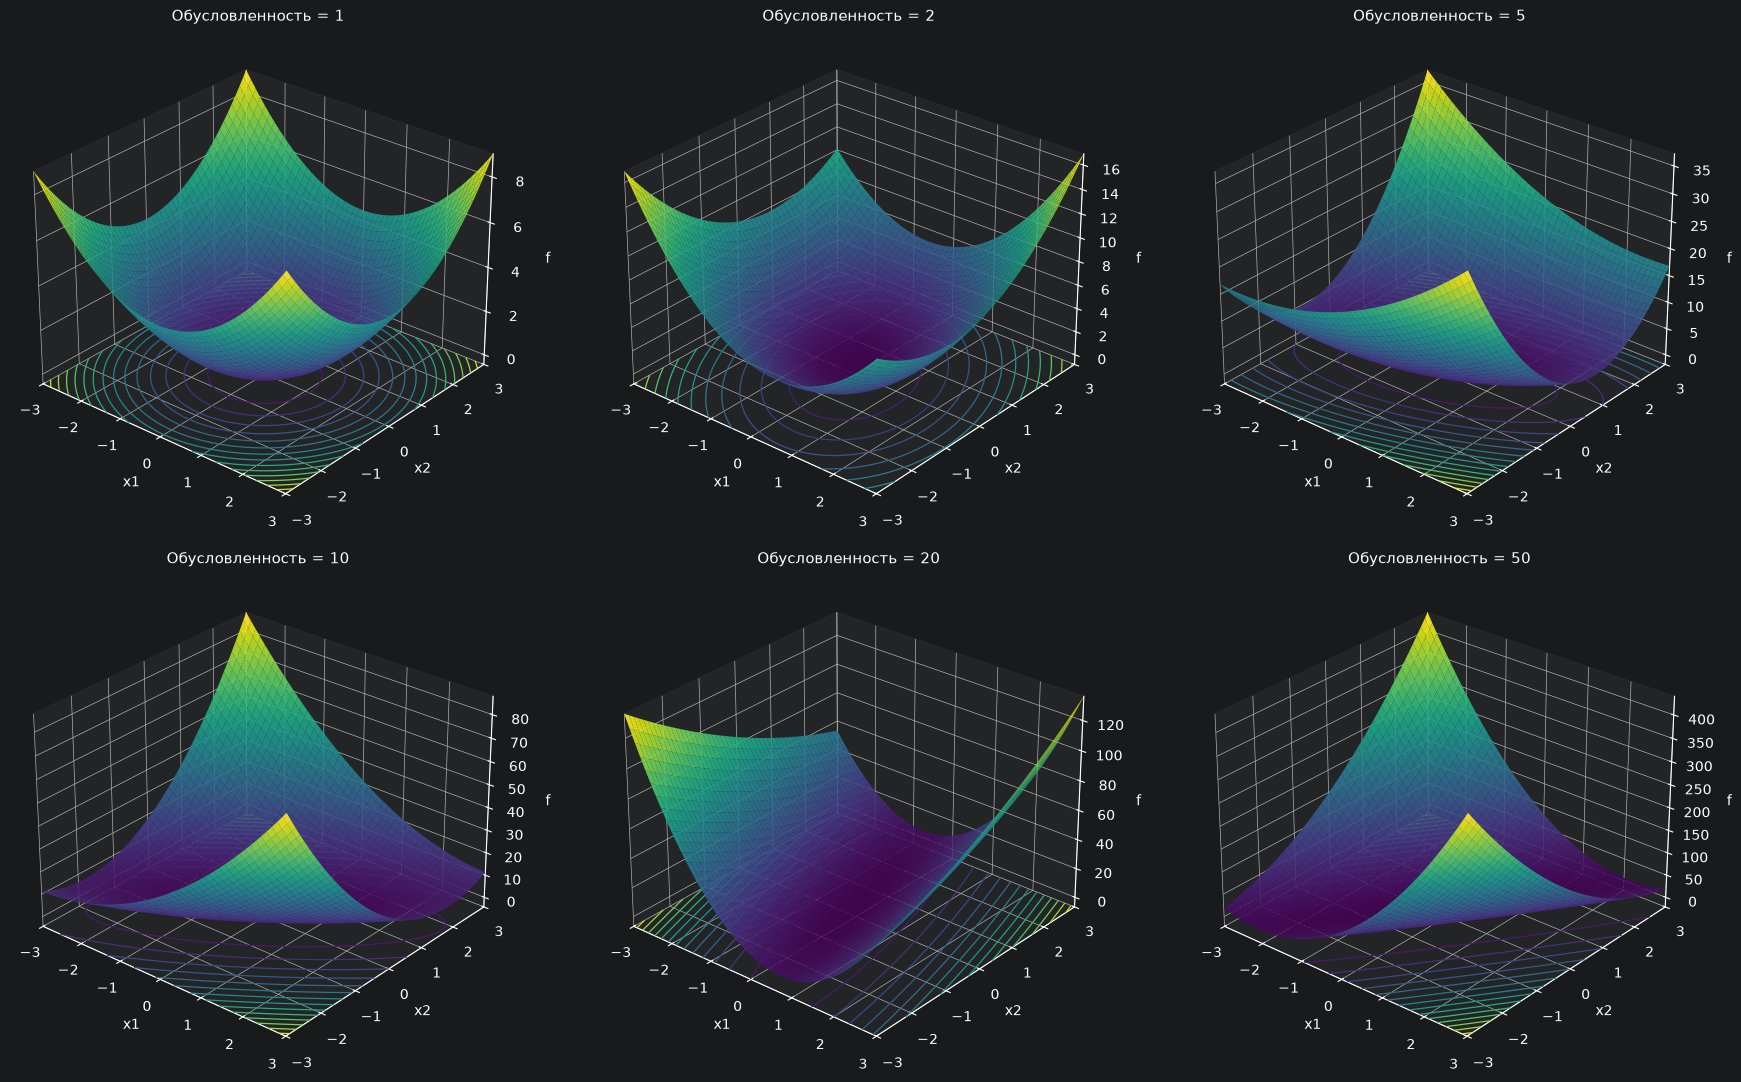

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def generate_quadratic(kappa, seed=None):
    rng = np.random.default_rng(seed)
    U, _ = np.linalg.qr(rng.standard_normal((2, 2)))
    A = U @ np.diag([1.0, kappa]) @ U.T
    return 0.5 * (A + A.T)

def quadratic(X, Y, A):
    return 0.5 * (A[0, 0]*X**2 + 2*A[0, 1]*X*Y + A[1, 1]*Y**2)


kappas = [1, 2, 5, 10, 20, 50]
L = 3.0
X, Y = np.meshgrid(np.linspace(-L, L, 150), np.linspace(-L, L, 150))

fig = plt.figure(figsize=(18, 11))
for i, kappa in enumerate(kappas, 1):
    ax = fig.add_subplot(2, 3, i, projection='3d')
    A = generate_quadratic(kappa, seed=kappa)
    Z = quadratic(X, Y, A)
    z_off = -0.05 * Z.max()

    ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.92,
                    rstride=3, cstride=3)
    ax.contour(X, Y, Z, zdir='z', offset=z_off, levels=15,
               cmap='viridis', linewidths=0.9)

    ax.set_title(f"Обусловленность = {kappa}", fontsize=11)
    ax.set(xlabel='x1', ylabel='x2', zlabel='f',
           xlim=(-L, L), ylim=(-L, L), zlim=(z_off, Z.max()))
    ax.view_init(elev=28, azim=-50)

plt.tight_layout()
plt.show()